In [3]:
#1. Setting Up
#Here I import the data and ensure the structure aligns with that suggested at the data source
#I also previewed the first few rows of the cleaned data to be sure it looks as anticipated
# We also dropped the lines with missing data since there were only 6 total, so a minimal loss
import pandas as pd
import numpy as np

file_path = "processed.cleveland.data"
column_names = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]
df = pd.read_csv(file_path, names=column_names)
df['ca'] = pd.to_numeric(df['ca'], errors='coerce')
df['thal'] = pd.to_numeric(df['thal'], errors='coerce')


print("Missing values per column:")
print(df.isna().sum())

df = df.dropna()

df['target'] = (df['target'] > 0).astype(int)

print("\nCleaned Data Preview:")
print(df.head())

print("\nClass Distribution:")
print(df['target'].value_counts())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Cleaned Data Preview:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       1  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  

Class Distribution:
0    160
1    137
Name: target, dtype: int64


In [4]:
#2. Splitting
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
#Here I separate the data into training and testing sets and set up the scale numeric features/view data shape afterwards
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (237, 13)
Testing shape: (60, 13)


In [9]:
#3. Trying 1st Model: Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall: {recall_score(y_test, y_pred):.3f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.3f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba):.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=3))

Logistic Regression Results:
Accuracy: 0.833
Precision: 0.846
Recall: 0.786
F1 Score: 0.815
AUC-ROC: 0.950

Confusion Matrix:
[[28  4]
 [ 6 22]]

Classification Report:
              precision    recall  f1-score   support

           0      0.824     0.875     0.848        32
           1      0.846     0.786     0.815        28

    accuracy                          0.833        60
   macro avg      0.835     0.830     0.832        60
weighted avg      0.834     0.833     0.833        60



In [10]:
#3.5 Tuning Logistic Reg Model
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['liblinear', 'lbfgs']
}

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_lr.fit(X_train_scaled, y_train)
best_lr = grid_lr.best_estimator_

y_pred_lr_best = best_lr.predict(X_test_scaled)
y_proba_lr_best = best_lr.predict_proba(X_test_scaled)[:, 1]

print(f"Best Logistic Regression Parameters: {grid_lr.best_params_}")
print(f"Logistic Regression - Accuracy: {accuracy_score(y_test, y_pred_lr_best):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_lr_best):.3f}")
print(f"Recall: {recall_score(y_test, y_pred_lr_best):.3f}")
print(f"F1 Score: {f1_score(y_test, y_pred_lr_best):.3f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_lr_best):.3f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr_best, digits=3))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Logistic Regression Parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Logistic Regression - Accuracy: 0.867
Precision: 0.917
Recall: 0.786
F1 Score: 0.846
AUC-ROC: 0.951

Classification Report:
               precision    recall  f1-score   support

           0      0.833     0.938     0.882        32
           1      0.917     0.786     0.846        28

    accuracy                          0.867        60
   macro avg      0.875     0.862     0.864        60
weighted avg      0.872     0.867     0.865        60



In [11]:
#4. Trying 2nd Model: Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
y_proba_rf = rf.predict_proba(X_test_scaled)[:, 1]

print("Random Forest Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.3f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.3f}")
print(f"F1 Score: {f1_score(y_test, y_pred_rf):.3f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_rf):.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, digits=3))

Random Forest Results:
Accuracy: 0.867
Precision: 0.885
Recall: 0.821
F1 Score: 0.852
AUC-ROC: 0.941

Confusion Matrix:
[[29  3]
 [ 5 23]]

Classification Report:
              precision    recall  f1-score   support

           0      0.853     0.906     0.879        32
           1      0.885     0.821     0.852        28

    accuracy                          0.867        60
   macro avg      0.869     0.864     0.865        60
weighted avg      0.868     0.867     0.866        60



In [12]:
#4.5 Tuned Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None], 
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']  
}

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train_scaled, y_train)
best_rf = grid_rf.best_estimator_

y_pred_rf_best = best_rf.predict(X_test_scaled)
y_proba_rf_best = best_rf.predict_proba(X_test_scaled)[:, 1]

print(f"Best Random Forest Parameters: {grid_rf.best_params_}")
print(f"Random Forest - Accuracy: {accuracy_score(y_test, y_pred_rf_best):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_rf_best):.3f}")
print(f"Recall: {recall_score(y_test, y_pred_rf_best):.3f}")
print(f"F1 Score: {f1_score(y_test, y_pred_rf_best):.3f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_rf_best):.3f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf_best, digits=3))

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best Random Forest Parameters: {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Random Forest - Accuracy: 0.867
Precision: 0.885
Recall: 0.821
F1 Score: 0.852
AUC-ROC: 0.946

Classification Report:
               precision    recall  f1-score   support

           0      0.853     0.906     0.879        32
           1      0.885     0.821     0.852        28

    accuracy                          0.867        60
   macro avg      0.869     0.864     0.865        60
weighted avg      0.868     0.867     0.866        60



In [8]:
#5. Trying 3rd Model: SVC
from sklearn.svm import SVC

svm_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)
y_proba_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

print("SVM Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))
print("AUC-ROC:", roc_auc_score(y_test, y_proba_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Results:
Accuracy: 0.85
Precision: 0.88
Recall: 0.7857142857142857
F1 Score: 0.830188679245283
AUC-ROC: 0.9542410714285714

Confusion Matrix:
[[29  3]
 [ 6 22]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.91      0.87        32
           1       0.88      0.79      0.83        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60



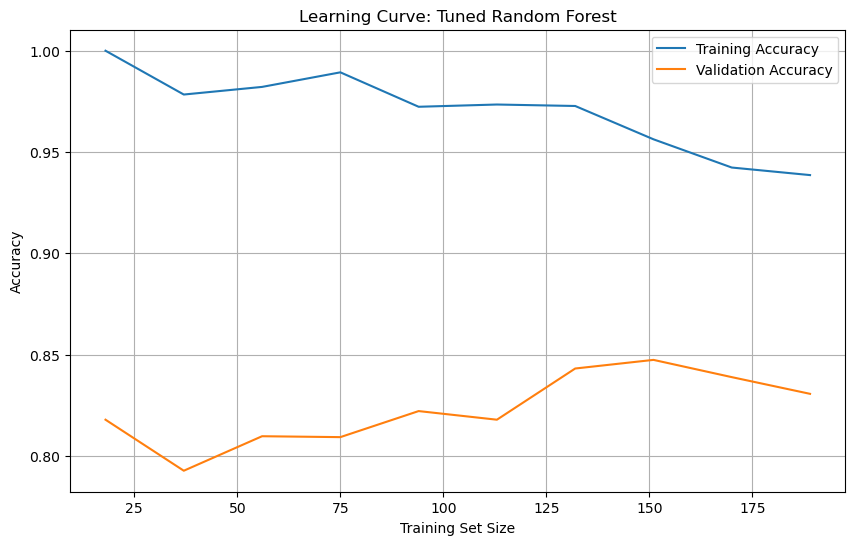

In [21]:
#6. Variance vs. Bias
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    best_rf,  
    X_train_scaled, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Plot it again
import matplotlib.pyplot as plt
import numpy as np

train_scores_mean = np.mean(train_scores, axis=1)
val_scores_mean = np.mean(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_scores_mean, label="Training Accuracy")
plt.plot(train_sizes, val_scores_mean, label="Validation Accuracy")
plt.xlabel("Training Set Size")
plt.ylabel("Accuracy")
plt.title("Learning Curve: Tuned Random Forest")
plt.legend()
plt.grid(True)
plt.show()


In [22]:
#7. Hyperparameter Tuning (Extended for Performance) 
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],             
    'max_depth': [5, 10, 15],                    
    'min_samples_split': [2, 5],                
    'min_samples_leaf': [1, 2],                  
    'max_features': ['sqrt', 'log2', None]       
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

best_rf = grid_search.best_estimator_

y_pred_best = best_rf.predict(X_test_scaled)
y_proba_best = best_rf.predict_proba(X_test_scaled)[:, 1]

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)
print("\nTest Accuracy with Best Model:", accuracy_score(y_test, y_pred_best))
print("Test F1 Score:", f1_score(y_test, y_pred_best))
print("Test AUC-ROC:", roc_auc_score(y_test, y_proba_best))
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))


Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.8349290780141843

Test Accuracy with Best Model: 0.85
Test F1 Score: 0.830188679245283
Test AUC-ROC: 0.9508928571428572

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.91      0.87        32
           1       0.88      0.79      0.83        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60



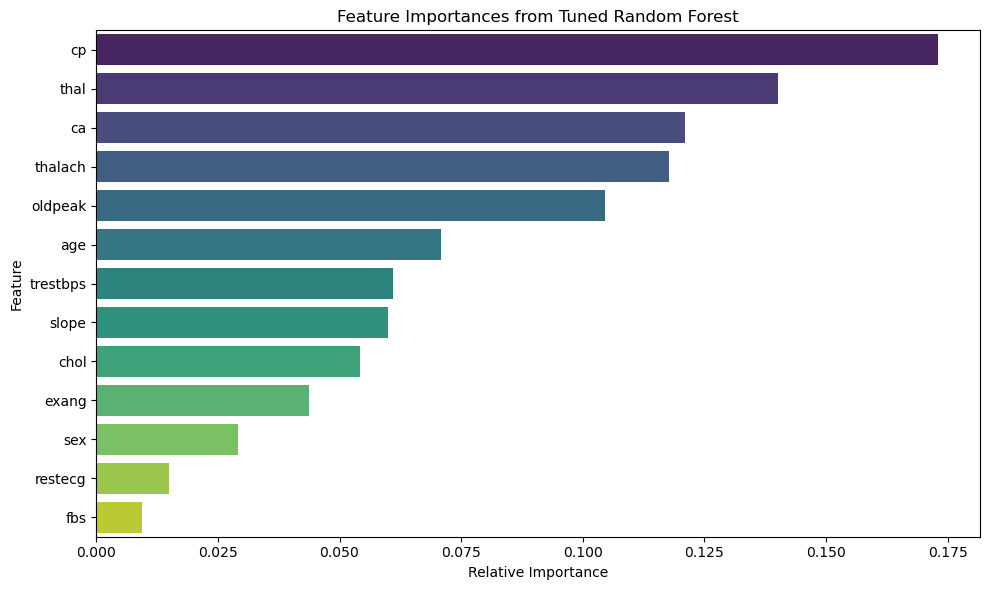

In [23]:
#8. Feature Importance 
import matplotlib.pyplot as plt
import seaborn as sns

importances = best_rf.feature_importances_
feature_names = X.columns  

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='viridis')
plt.title('Feature Importances from Tuned Random Forest')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()